# 04 — Lead-Lag, Presedensi Prediktif & Sinyal Semalam EIDO

**Phase 4/7 — Lead-lag & efek zona waktu.** Phase 3 menunjukkan bahwa seri yang tutup *setelah* IHSG tampak lemah di korelasi harian hari yang sama tetapi kuat di mingguan. Phase ini menguji urutan waktunya secara langsung: apakah yang terjadi di New York malam ini (S&P 500, EEM, VIX, komoditas, rupiah, dan EIDO) mendahului pergerakan IHSG besok?

Ada empat alat:
1. Cross-correlation per lag.
2. Regresi lead dengan standard error HAC.
3. **Granger, sebagai uji presedensi prediktif.** "X Granger-mendahului IHSG" hanya berarti masa lalu X menambah daya jelas statistik bagi IHSG; **bukan** berarti X menyebabkan IHSG bergerak.
4. Premium/diskon EIDO terhadap IHSG dalam USD.

**Aturan yang berlaku:**
- **Semua estimasi hanya memakai 2010–2019** (keputusan kebersihan OOS). Data 2020+ tidak disentuh sampai Phase 6.
- Harga USD/IDR ber-`flag_stale_quote` dibuang. Versi lengkap ditampilkan sebagai sensitivitas.
- Hasil di sini adalah **asosiasi/presedensi in-sample, bukan sinyal**. Tabel dengan banyak uji memakai koreksi Benjamini–Hochberg (`*_bh`).

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import analysis as an
from src import leadlag as ll
from src import plots
from src import preprocess as pp
from src.config import load_config, output_dir, series_table, target_ticker
from src.data_loader import load_prices

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

cfg = load_config()
lcfg = cfg["analysis"]["leadlag"]
series = series_table(cfg, groups=("target", "core", "tools"))
target_id, fx_id, eido_id = cfg["project"]["target_id"], cfg["usdidr_retest"]["id"], lcfg["eido_id"]
core = [s["id"] for s in cfg["core"]]
sessions = dict(zip(series["id"], series["session"]))
after_ids = [i for i in core if sessions[i] == "after"]
names = dict(zip(series["id"], series["name"]))
labels = series.set_index("id")["label"].rename("label")
transforms = dict(zip(series["id"], series["transform"]))
start, end = cfg["project"]["screening_window"]           # IN-SAMPLE SAJA

proc = output_dir(cfg, "data/processed")
prices_is = ll.in_sample(pd.read_parquet(proc / "prices_clean.parquet").loc[start:], end)
flags_is = ll.in_sample(pd.read_parquet(proc / "stale_quote_flags.parquet").loc[start:], end)
close_main = ll.drop_flagged(prices_is, flags_is)          # keputusan: kuotasi basi dibuang
daily_main = pp.pair_daily_returns(close_main, target_id, transforms)
daily_full = pp.pair_daily_returns(prices_is, target_id, transforms, flags_is)   # sensitivitas
print(f"In-sample: {prices_is.index.min():%d %b %Y} s/d {prices_is.index.max():%d %b %Y} | "
      f"harga USD/IDR dibuang karena basi: {int(flags_is[fx_id].sum())}")
print("Sesi 'after':", after_ids, "| sesi 'sync':", [i for i in core if sessions[i] == "sync"])

In-sample: 01 Jan 2010 s/d 31 Dec 2019 | harga USD/IDR dibuang karena basi: 25
Sesi 'after': ['EEM', 'SPX', 'NIFTY', 'VIX', 'COPPER', 'BRENT', 'USDIDR'] | sesi 'sync': ['STI', 'KLCI', 'HSI']


## 1. Cross-correlation: IHSG(t+k) vs seri(t)

Untuk tiap pasangan IHSG–seri, t adalah urutan tanggal yang **sama-sama buka**. Nilai k > 0 berarti seri mendahului IHSG; k = +1 berarti pergerakan seri hari ini dibandingkan dengan IHSG di hari bursa bersama berikutnya.

Hipotesis dari jam perdagangan:
- Seri sesi **"after"** (tutup setelah 16:00 WIB) puncaknya di **k = +1**.
- Seri **"sync"** (Singapura, Malaysia, Hong Kong) puncaknya di **k = 0**.

CI 95% memakai Fisher z, dan p-value dikoreksi BH atas seluruh 10 × 11 korelasi.

,k_puncak,r_puncak,p_bh_puncak,r_k0,r_k1,name,session
id,,,,,,,
USDIDR,-1,-0.135,0.0,-0.091,-0.038,USD/IDR,after
BRENT,0,0.117,0.0,0.117,0.109,Brent,after
COPPER,0,0.167,0.0,0.167,0.122,Tembaga,after
NIFTY,0,0.422,0.0,0.422,0.086,Nifty 50,after
EEM,1,0.379,0.0,0.265,0.379,iShares MSCI EM,after
SPX,1,0.336,0.0,0.159,0.336,S&P 500,after
VIX,1,-0.268,0.0,-0.131,-0.268,VIX,after
HSI,0,0.517,0.0,0.517,0.006,Hang Seng,sync
KLCI,0,0.500,0.0,0.500,0.010,KLCI Malaysia,sync


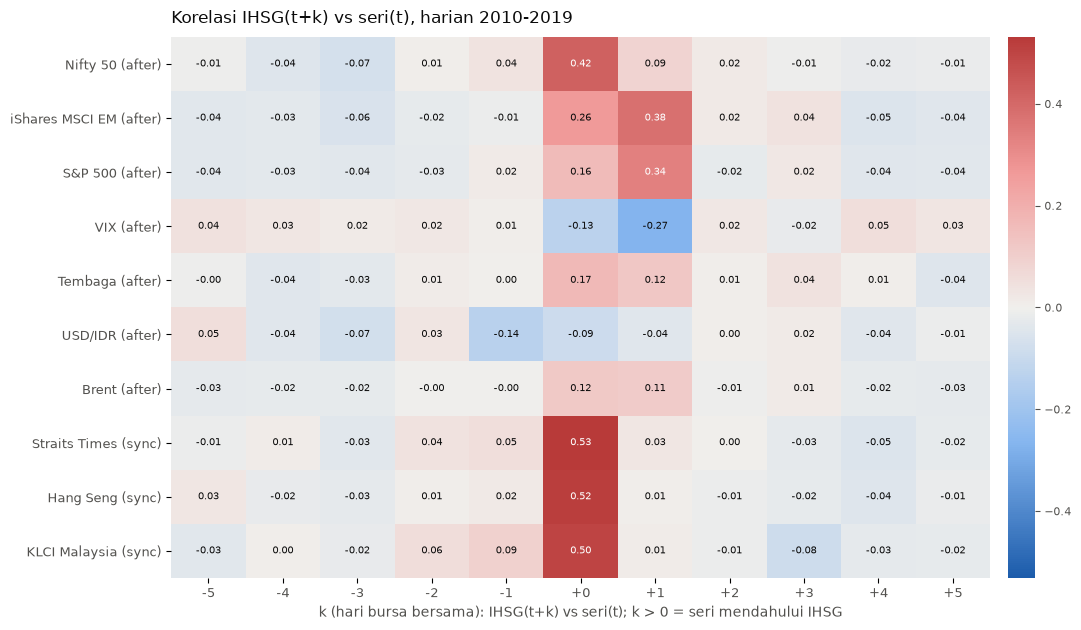

In [2]:
ccf = ll.cross_correlation(daily_main, core, lcfg["max_k"])
peaks = ll.ccf_peaks(ccf, series)
display(peaks.round(3))
fig = plots.plot_ccf_heatmap(ccf, names, sessions, "Korelasi IHSG(t+k) vs seri(t), harian 2010-2019")

In [3]:
# CI dan BH untuk k = 0 dan k = +1
k01 = ccf[ccf["k"].isin([0, 1])].pivot(index="id", columns="k", values=["r", "ci_lo", "ci_hi", "p_bh"])
k01.reindex(core).round(3)

r         ci_lo         ci_hi        p_bh       
k           0      1      0      1      0      1    0      1
id                                                          
STI     0.531  0.029  0.502 -0.011  0.560  0.069  0.0  0.321
KLCI    0.500  0.010  0.469 -0.030  0.530  0.051  0.0  0.741
EEM     0.265  0.379  0.227  0.344  0.302  0.413  0.0  0.000
SPX     0.159  0.336  0.120  0.300  0.198  0.371  0.0  0.000
NIFTY   0.422  0.086  0.388  0.046  0.455  0.127  0.0  0.000
HSI     0.517  0.006  0.487 -0.035  0.546  0.046  0.0  0.836
VIX    -0.131 -0.268 -0.170 -0.305 -0.091 -0.231  0.0  0.000
COPPER  0.167  0.122  0.128  0.082  0.206  0.161  0.0  0.000
BRENT   0.117  0.109  0.077  0.069  0.157  0.149  0.0  0.000
USDIDR -0.091 -0.038 -0.131 -0.078 -0.051  0.002  0.0  0.175

## 2. Regresi lead: IHSG(t+1) ~ seri sesi "after" (t)

- **Satu faktor:** per pasangan, di tanggal yang sama-sama buka.
- **Multi-faktor:** semua seri "after" sekaligus, di tanggal yang **semua** seri buka (lebih sedikit observasi). Standard error HAC dengan lag = ⌊4(T/100)^(2/9)⌋.
- **Cek tambahan:** model multi-faktor plus return IHSG hari t sebagai kontrol momentum.

Beta dibaca sebagai: seri naik 1% malam ini ↔ IHSG besok rata-rata berubah β% (asosiasi in-sample).

In [4]:
lead_1f = ll.pair_lead_betas(daily_main, after_ids)
grid = ll.grid_returns(close_main, [target_id] + after_ids, transforms)
lf = ll.lead_frame(grid, target_id)
lead_multi, lead_model = an.factor_regression(lf, "target_lead", after_ids, None, None)
lead_ctrl, lead_ctrl_model = an.factor_regression(lf, "target_lead", after_ids + [target_id], None, None)
vif_lead = an.vif_table(lf, after_ids, None, None)
lead_view = (lead_1f[["beta", "ci_lo", "ci_hi", "p_bh", "r2", "n"]].add_suffix("_1f")
             .join(lead_multi[["beta", "ci_lo", "ci_hi", "p_bh"]].add_suffix("_multi"))
             .join(lead_ctrl[["beta", "p_bh"]].add_suffix("_multi+IHSG(t)")).join(vif_lead).join(labels))
print(f"Multi-faktor: n = {lead_model['n_minggu']} hari, R² = {lead_model['r2']:.3f} | "
      f"+ IHSG(t): R² = {lead_ctrl_model['r2']:.3f}, beta IHSG(t) = {lead_ctrl.loc[target_id, 'beta']:+.3f} "
      f"(p_bh {lead_ctrl.loc[target_id, 'p_bh']:.3f})")
lead_view.round(4)

Multi-faktor: n = 2187 hari, R² = 0.127 | + IHSG(t): R² = 0.128, beta IHSG(t) = -0.048 (p_bh 0.151)


,beta_1f,ci_lo_1f,ci_hi_1f,p_bh_1f,r2_1f,n_1f,beta_multi,ci_lo_multi,ci_hi_multi,p_bh_multi,beta_multi+IHSG(t),p_bh_multi+IHSG(t),vif,label
id,,,,,,,,,,,,,,
EEM,0.2912,0.2547,0.3276,0.0000,0.1438,2372,0.2691,0.1946,0.3435,0.0000,0.2771,0.0000,3.7374,
SPX,0.3675,0.3130,0.4220,0.0000,0.1127,2372,0.0959,-0.0187,0.2104,0.1765,0.0897,0.2542,4.7242,
NIFTY,0.0925,0.0429,0.1421,0.0003,0.0075,2313,-0.0635,-0.1263,-0.0006,0.1113,-0.0449,0.2599,1.2075,
VIX,-0.0357,-0.0425,-0.0289,0.0000,0.0720,2372,0.0025,-0.0066,0.0117,0.8238,0.0025,0.7988,2.8873,
COPPER,0.0891,0.0527,0.1255,0.0000,0.0148,2369,-0.0666,-0.1125,-0.0206,0.0159,-0.0651,0.0201,1.3387,
BRENT,0.0580,0.0361,0.0798,0.0000,0.0118,2339,-0.0007,-0.0233,0.0218,0.9495,-0.0009,0.9401,1.1999,dipilih dengan pengetahuan periode uji
USDIDR,-0.0602,-0.1439,0.0234,0.1584,0.0014,2396,-0.0024,-0.0743,0.0694,0.9495,-0.0098,0.9039,1.0093,


In [5]:
lines = ["**Dalam bahasa skenario (asosiasi in-sample 2010-2019, multi-faktor):**", ""]
for sid, r in lead_multi.iterrows():
    sig = "signifikan setelah BH" if r.p_bh < 0.05 else "tidak signifikan setelah BH"
    lines.append(f"- {names[sid]} naik 1% malam ini ↔ IHSG besok rata-rata {r.beta:+.3f}% "
                 f"(CI {r.ci_lo:+.3f}% s/d {r.ci_hi:+.3f}%); {sig}" + (f" *({labels[sid]})*" if labels[sid] else "") + ".")
display(Markdown("\n".join(lines)))

**Dalam bahasa skenario (asosiasi in-sample 2010-2019, multi-faktor):**

- iShares MSCI EM naik 1% malam ini ↔ IHSG besok rata-rata +0.269% (CI +0.195% s/d +0.344%); signifikan setelah BH.
- S&P 500 naik 1% malam ini ↔ IHSG besok rata-rata +0.096% (CI -0.019% s/d +0.210%); tidak signifikan setelah BH.
- Nifty 50 naik 1% malam ini ↔ IHSG besok rata-rata -0.063% (CI -0.126% s/d -0.001%); tidak signifikan setelah BH.
- VIX naik 1% malam ini ↔ IHSG besok rata-rata +0.003% (CI -0.007% s/d +0.012%); tidak signifikan setelah BH.
- Tembaga naik 1% malam ini ↔ IHSG besok rata-rata -0.067% (CI -0.113% s/d -0.021%); signifikan setelah BH.
- Brent naik 1% malam ini ↔ IHSG besok rata-rata -0.001% (CI -0.023% s/d +0.022%); tidak signifikan setelah BH *(dipilih dengan pengetahuan periode uji)*.
- USD/IDR naik 1% malam ini ↔ IHSG besok rata-rata -0.002% (CI -0.074% s/d +0.069%); tidak signifikan setelah BH.

## 3. Granger: presedensi prediktif dua arah

Untuk tiap pasangan dipakai VAR bivariat return harian 2010–2019.
- **Orde lag:** dipilih **BIC** (mengikat, sesuai rencana yang dikunci; maks. 5). AIC ditampilkan sebagai pembanding.
- **Uji:** Wald F dengan kovarians HAC, bahwa semua lag penyebab = 0.
- **Arah:** dua arah, seri → IHSG dan IHSG → seri.

**Ini uji presedensi prediktif, bukan sebab-akibat.** Seri sesi "after" punya keuntungan mekanis dari jam perdagangan: lag 1-nya sudah memuat informasi yang terjadi setelah IHSG tutup. Karena itu presedensi seri "after" → IHSG memang diharapkan dan tidak berarti kausal.

In [6]:
granger = ll.granger_table(daily_main, core, lcfg["granger_maxlags"], lcfg["granger_ic"])
granger.join(series.set_index("id")["session"]).join(labels).round(4)

,lag_aic,lag_bic,lag_dipakai,F_seri_ke_target,p_seri_ke_target,n_seri_ke_target,F_target_ke_seri,p_target_ke_seri,n_target_ke_seri,p_seri_ke_target_bh,p_target_ke_seri_bh,session,label
id,,,,,,,,,,,,,
STI,4,0,1,0.1791,0.6722,2381,1.7952,0.1804,2381,0.7469,0.6014,sync,
KLCI,5,0,1,0.0941,0.7590,2348,6.1622,0.0131,2348,0.7590,0.0656,sync,
EEM,5,3,3,89.5911,0.0000,2370,1.3001,0.2727,2370,0.0000,0.6817,after,
SPX,5,1,1,164.9143,0.0000,2372,0.5097,0.4754,2372,0.0000,0.8348,after,
NIFTY,3,0,1,13.9362,0.0002,2313,0.2057,0.6502,2313,0.0003,0.8348,after,
HSI,4,0,1,0.5597,0.4545,2334,0.1842,0.6678,2334,0.5681,0.8348,sync,
VIX,5,1,1,98.5700,0.0000,2372,0.0025,0.9602,2372,0.0000,0.9602,after,
COPPER,4,1,1,21.3169,0.0000,2369,0.2027,0.6526,2369,0.0000,0.8348,after,
BRENT,5,1,1,23.9769,0.0000,2339,0.0597,0.8070,2339,0.0000,0.8966,after,dipilih dengan pengetahuan periode uji


## 4. Sinyal semalam EIDO

EIDO (iShares MSCI Indonesia) diperdagangkan di New York, jadi ia "IHSG yang terus bergerak setelah Jakarta tutup". Timing pada tanggal t:
- **IHSG** tutup 16:00 WIB.
- **IDR=X dan EIDO** tutup di sesi AS (dini hari WIB, t+1).
- **IHSG dalam USD** = IHSG(t) / USDIDR(t).

Dari situ:
- **Premium** = log EIDO(t) − log IHSG_USD(t): perbedaan level yang memuat pergerakan saham Indonesia (dalam USD) setelah IHSG tutup, plus basis karena EIDO melacak MSCI Indonesia dan memuat dividen, sedangkan IHSG adalah indeks harga.
- **Δpremium(t)** = return EIDO − return IHSG_USD: bagian pergerakan EIDO hari itu yang **belum** ada di harga penutupan IHSG.

Langkah: uji kointegrasi log EIDO vs log IHSG_USD (Engle–Granger, Johansen sebagai cek). Kalau terkointegrasi, dilaporkan z-score spread dan half-life. Lalu diuji apakah return EIDO, Δpremium, dan z-score spread berasosiasi dengan IHSG(t+1), dan apakah informasinya **tambahan** di atas S&P 500(t) dan EEM(t).

**Aturan keputusan:** "terkointegrasi" ditentukan oleh Engle–Granger dengan konstanta (α = 5%). Versi dengan tren dan Johansen dilaporkan sebagai cek. Kalau tidak terkointegrasi, yang dipakai adalah Δpremium, sesuai rencana yang dikunci. Catatan: harga EIDO di Yahoo sudah disesuaikan dividen (total return), sedangkan IHSG adalah indeks harga, jadi spread wajar punya tren naik kira-kira sebesar dividend yield.

In [7]:
ef = ll.eido_frame(close_main, target_id, fx_id, eido_id, lcfg["eido_compare_ids"], transforms)
co = ll.cointegration(ef["log_eido"], ef["log_target_usd"], lcfg["coint_alpha"])
display(pd.Series(co).to_frame("nilai"))
if co["terkointegrasi"]:
    ef["spread_z"] = ll.spread_zscore(ef["log_eido"], ef["log_target_usd"], co)
    fig = plots.plot_spread_z(ef["spread_z"], "z-score spread EIDO vs IHSG dalam USD (in-sample 2010-2019)")

,nilai
n,2249
mulai,2010-05-10 00:00:00
akhir,2019-12-27 00:00:00
eg_c_stat,-3.044518
eg_c_p,0.099999
eg_ct_stat,-6.150116
eg_ct_p,0.000005
johansen_trace_r0,82.39269
johansen_crit95_r0,15.4943
johansen_r0_ditolak,True


In [8]:
cmp = [f"r_{c}" for c in lcfg["eido_compare_ids"]]
models = {"pembanding (S&P, EEM)": cmp,
          "EIDO saja": ["r_eido"],
          "Δpremium saja": ["d_premium"],
          "pembanding + EIDO": cmp + ["r_eido"],
          "pembanding + Δpremium": cmp + ["d_premium"]}
if co["terkointegrasi"]:
    models["pembanding + Δpremium + z spread"] = cmp + ["d_premium", "spread_z"]
    models["pembanding + Δpremium + z spread + IHSG(t)"] = cmp + ["d_premium", "spread_z", "r_target"]
eido_coef, eido_models = ll.nested_regressions(ef, "target_lead", models, "pembanding (S&P, EEM)")
display(eido_models.round(4))
eido_coef.round(4)

,regresor,n,hac_lags,r2,adj_r2,tambahan_r2_vs_base,F_tambahan,p_tambahan
model,,,,,,,,
"pembanding (S&P, EEM)",r_SPX + r_EEM,2249,7,0.1323,0.1315,NaN,NaN,NaN
EIDO saja,r_eido,2249,7,0.1194,0.1190,NaN,NaN,NaN
Δpremium saja,d_premium,2249,7,0.1248,0.1244,NaN,NaN,NaN
pembanding + EIDO,r_SPX + r_EEM + r_eido,2249,7,0.1466,0.1455,0.0144,20.5847,0.0
pembanding + Δpremium,r_SPX + r_EEM + d_premium,2249,7,0.1548,0.1536,0.0225,33.1445,0.0


,model,variabel,beta,ci_lo,ci_hi,t_hac,p
0,"pembanding (S&P, EEM)",r_SPX,0.0914,-0.0075,0.1902,1.8112,0.0701
1,"pembanding (S&P, EEM)",r_EEM,0.2249,0.1546,0.2952,6.2727,0.0000
2,EIDO saja,r_eido,0.2076,0.1735,0.2417,11.9459,0.0000
3,Δpremium saja,d_premium,0.2474,0.2126,0.2822,13.9224,0.0000
4,pembanding + EIDO,r_SPX,0.0948,-0.0029,0.1925,1.9014,0.0573
5,pembanding + EIDO,r_EEM,0.1231,0.0571,0.1891,3.6555,0.0003
6,pembanding + EIDO,r_eido,0.1061,0.0603,0.1519,4.5370,0.0000
7,pembanding + Δpremium,r_SPX,0.0662,-0.0296,0.1619,1.3540,0.1757
8,pembanding + Δpremium,r_EEM,0.1377,0.0626,0.2128,3.5935,0.0003
9,pembanding + Δpremium,d_premium,0.1403,0.0925,0.1880,5.7571,0.0000


## 5. Dampak timing USD/IDR: apakah rupiah berperilaku seperti seri "after"?

Bar harian IDR=X tutup di jam AS, jadi kurs "hari t" sudah memuat kabar sesi Eropa/AS setelah IHSG tutup. Kalau begitu, rupiah seharusnya berperilaku seperti seri "after": korelasi hari yang sama lemah, dan ada hubungan dengan IHSG(t+1).

Perbandingan juga dibuat dengan dan tanpa kuotasi basi.

In [9]:
ccf_full = ll.cross_correlation(daily_full, [fx_id], lcfg["max_k"])
fx_view = pd.DataFrame({
    "r_k0 (bersih)": ccf.query("id == @fx_id and k == 0")["r"].values,
    "r_k1 (bersih)": ccf.query("id == @fx_id and k == 1")["r"].values,
    "r_k0 (lengkap)": ccf_full.query("k == 0")["r"].values,
    "r_k1 (lengkap)": ccf_full.query("k == 1")["r"].values,
    "beta lead 1f": [lead_1f.loc[fx_id, "beta"]], "p_bh lead 1f": [lead_1f.loc[fx_id, "p_bh"]],
    "Granger rupiah→IHSG p_bh": [granger.loc[fx_id, "p_seri_ke_target_bh"]],
    "Granger IHSG→rupiah p_bh": [granger.loc[fx_id, "p_target_ke_seri_bh"]],
}, index=[fx_id])
fx_view.round(4)

,r_k0 (bersih),r_k1 (bersih),r_k0 (lengkap),r_k1 (lengkap),beta lead 1f,p_bh lead 1f,Granger rupiah→IHSG p_bh,Granger IHSG→rupiah p_bh
USDIDR,-0.0911,-0.0377,-0.071,-0.0431,-0.0602,0.1584,0.2192,0.0


## 6. Sensitivitas gap pembukaan (EKSPLORATIF)

Sesuai rencana yang dikunci (README, "Rencana untuk phase berikutnya"): hari dengan Open = Close kemarin dibuang, lalu return IHSG dipecah jadi gap pembukaan, log(Open t / Close t−1), dan intraday, log(Close t / Open t).

Di 2010–2019 masalah Open itu hanya terjadi di 0–0,4% hari per tahun; tahun-tahun yang bermasalah ada di luar periode ini. Pertanyaannya: apakah seri "after"(t) berasosiasi dengan **gap** pembukaan IHSG besok, atau dengan pergerakan **intraday**-nya?

**Hasil ini EKSPLORATIF** dan tidak dipakai untuk kesimpulan utama. Modul gap/intraday tetap tidak lolos untuk analisis utama (poin 7 README).

**Catatan artefak:** Open indeks dihitung dari harga pembukaan saham. Saham yang belum diperdagangkan di menit pertama masih memakai harga kemarin, sehingga gap pembukaan indeks cenderung **terlalu kecil**. Sebagian reaksi semalam karenanya ikut tercatat sebagai "intraday", jadi korelasi intraday sebaiknya dibaca sebagai batas atas.

In [10]:
ohlc = load_prices([target_ticker(cfg)], start=start, end=end, verbose=False)[target_ticker(cfg)]
ohlc = ll.in_sample(ohlc.loc[ohlc.index.isin(close_main[target_id].dropna().index)], end)
split = ll.open_gap_split(ohlc)
print(f"Hari dibuang (Open = Close kemarin) 2010-2019: {int(split['gap'].isna().sum())} dari {len(split)}")
gap_corr = ll.gap_lead_corr(daily_main, split, after_ids)
gap_corr.pivot(index="id", columns="bagian", values=["r", "ci_lo", "ci_hi", "p_bh"]).round(3)

Hari dibuang (Open = Close kemarin) 2010-2019: 5 dari 2436


r           ci_lo           ci_hi            p_bh         
bagian    gap intraday    gap intraday    gap intraday    gap intraday
id                                                                    
BRENT   0.182    0.049  0.143    0.008  0.221    0.089  0.000    0.022
COPPER  0.146    0.083  0.107    0.042  0.186    0.123  0.000    0.000
EEM     0.441    0.251  0.408    0.213  0.473    0.288  0.000    0.000
NIFTY   0.120    0.049  0.079    0.009  0.160    0.090  0.000    0.022
SPX     0.457    0.199  0.424    0.160  0.488    0.238  0.000    0.000
USDIDR -0.021   -0.035 -0.061   -0.075  0.020    0.005  0.315    0.095
VIX    -0.444   -0.134 -0.476   -0.173 -0.411   -0.094  0.000    0.000

## 7. Simpan hasil

Semua tabel disimpan ke `reports/phase4/`. Sebelum menyimpan, notebook memeriksa bahwa tidak ada data 2020+ yang ikut terpakai.

In [11]:
frames = {"daily_main": daily_main["Date"], "grid": lf.index.to_series(), "eido": ef.index.to_series(), "gap": split.index.to_series()}
assert all(pd.Series(v).max() <= pd.Timestamp(end) for v in frames.values()), "data 2020+ terpakai!"
tables = {"ccf": ccf, "ccf_puncak": peaks, "lead_satu_faktor": lead_1f, "lead_multi_faktor": lead_multi.join(vif_lead),
          "lead_multi_plus_ihsg_t": lead_ctrl, "granger": granger, "eido_koefisien": eido_coef, "eido_model": eido_models,
          "usdidr_timing": fx_view, "gap_eksploratif": gap_corr}
summary = {"in_sample": [start, end], "lead_multi_model": lead_model, "lead_multi_plus_ihsg_t_model": lead_ctrl_model,
           "eido_kointegrasi": co, "kuotasi_basi_dibuang": int(flags_is[fx_id].sum())}
paths = an.save_tables(output_dir(cfg, "reports", "phase4"), tables, summary)
print("Maks tanggal yang dipakai:", max(pd.Series(v).max() for v in frames.values()).date())
[p.name for p in paths]

Maks tanggal yang dipakai: 2019-12-30


['ccf.csv',
 'ccf_puncak.csv',
 'lead_satu_faktor.csv',
 'lead_multi_faktor.csv',
 'lead_multi_plus_ihsg_t.csv',
 'granger.csv',
 'eido_koefisien.csv',
 'eido_model.csv',
 'usdidr_timing.csv',
 'gap_eksploratif.csv',
 'summary.json']

## Ringkasan insight

Dibangun otomatis dari hasil di atas. Semua yang tertulis adalah **asosiasi/presedensi in-sample 2010–2019**; apakah polanya bertahan di 2020+ baru diuji di Phase 6.

In [12]:
display(Markdown(ll.phase4_summary(peaks, lead_multi, lead_model, granger, co, eido_models, names, fx_id, lead_1f)))

### Ringkasan Phase 4 (presedensi in-sample 2010-2019, BUKAN sinyal)

- **Pola waktu:** 3 dari 3 seri "sync" puncaknya di k = 0. Seri "after": k = -1: USD/IDR; k = +0: Brent, Tembaga, Nifty 50; k = +1: iShares MSCI EM, S&P 500, VIX.
- **Malam ini di New York → IHSG besok (regresi lead multi-faktor, R² 0.127):** iShares MSCI EM +1% → IHSG besok +27 bp; Tembaga +1% → IHSG besok -7 bp (tanda berbalik dari satu faktor +9 bp: efek tumpang tindih).
- **Presedensi prediktif (Granger, BH 5%):** seri → IHSG pada iShares MSCI EM, S&P 500, Nifty 50, VIX, Tembaga, Brent; IHSG → seri pada USD/IDR.
- **Rupiah (IDR=X):** r hari yang sama -0.091, hari berikutnya -0.038, puncak di k = -1.
- **EIDO vs IHSG dalam USD:** TIDAK terkointegrasi menurut aturan utama (Engle-Granger konstanta p = 0.100); cek: Engle-Granger + tren p = 4.51e-06, Johansen r=0 ditolak.
  - pembanding + EIDO: tambahan R² +0.014 di atas model pembanding, p (Wald HAC) = 6.01e-06.
  - pembanding + Δpremium: tambahan R² +0.022 di atas model pembanding, p (Wald HAC) = 9.73e-09.